
# TP1.EX1: Régression : Prédiction du tarif d’un trajet Uber
         Module:Thechnologie D'IA
           
           Filiere:ILIA2

           Réalisée par:Soumia Dahbi N:9
            
##Objectif
L'objectif de cet exercice est de prédire le prix (tarif) d'un trajet Uber à l'aide de techniques d'apprentissage supervisé (régression), en suivant un workflow complet : du chargement des données brutes, leur nettoyage et l'ingénierie des caractéristiques (feature engineering), jusqu'à l'entraînement, l'évaluation et la comparaison de modèles de régression (Régression Linéaire et Random Forest).

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement du jeu de données Uber via un lien direct brut (Raw) compatible avec Colab
url = "https://raw.githubusercontent.com/armandoordonez/eda_couse/main/data/uber.csv"
data = pd.read_csv(url)

print("--- Premières lignes ---")
display(data.head())

print("\n--- Informations générales ---")
data.info()

print("\n--- Valeurs manquantes ---")
print(data.isnull().sum())

--- Premières lignes ---


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5



--- Informations générales ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB

--- Valeurs manquantes ---
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


**Étape 2 : Nettoyage et préparation**

On supprime les valeurs manquantes et aberrantes, puis on extrait les informations temporelles (heure et jour de la semaine) à partir de la date de la course

In [5]:
# 1. Suppression des valeurs manquantes
data = data.dropna()

# 2. Retrait des valeurs aberrantes (si la colonne cible se nomme 'fare' ou 'fare_amount')
target_col = 'fare' if 'fare' in data.columns else 'fare_amount'
data = data[data[target_col] > 0]

# 3. Conversion de la date et création de variables dérivées (heure, jour de la semaine)
date_col = 'pickup_datetime'
data[date_col] = pd.to_datetime(data[date_col])
data['hour'] = data[date_col].dt.hour
data['day_of_week'] = data[date_col].dt.dayofweek

print("Aperçu après nettoyage et préparation :")
display(data[[date_col, 'hour', 'day_of_week', target_col]].head())

Aperçu après nettoyage et préparation :


,pickup_datetime,hour,day_of_week,fare_amount
0,2015-05-07 19:52:06+00:00,19,3,7.5
1,2009-07-17 20:04:56+00:00,20,4,7.7
2,2009-08-24 21:45:00+00:00,21,0,12.9
3,2009-06-26 08:22:21+00:00,8,4,5.3
4,2014-08-28 17:47:00+00:00,17,3,16.0


**Étape 3 : Séparation des données**

On sépare les variables explicatives (`X`) de la variable cible à prédire (`y`), puis on découpe le jeu de données en un ensemble d'entraînement et de test (80% / 20%)

In [6]:
from sklearn.model_selection import train_test_split

# Gestion automatique du nom de la colonne distance si besoin
dist_col = 'distance' if 'distance' in data.columns else 'trip_distance' if 'trip_distance' in data.columns else 'passenger_count'

X = data[['hour', 'day_of_week']] # Vous pouvez rajouter 'distance' ou des coordonnées si présentes
y = data[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Taille de X_train : {X_train.shape}")
print(f"Taille de X_test  : {X_test.shape}")

Taille de X_train : (159981, 2)
Taille de X_test  : (39996, 2)


**Étape 4 : Entraînement du modèle (Régression Linéaire)**


On initialise et on entraîne un modèle de Régression Linéaire sur l'ensemble d'entraînement, puis on effectue des prédictions sur l'ensemble de test

In [7]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)
print("Modèle de Régression Linéaire entraîné avec succès !")

Modèle de Régression Linéaire entraîné avec succès !


**Étape 5 : Évaluation du modèle**

On évalue les performances du modèle de régression à l'aide de métriques clés : MAE, RMSE et $R^2$

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('--- Performances de la Régression Linéaire ---')
print(f'MAE  = {mae:.4f}')
print(f'RMSE = {rmse:.4f}')
print(f'R²   = {r2:.4f}')

--- Performances de la Régression Linéaire ---
MAE  = 6.0271
RMSE = 9.6391
R²   = 0.0008


**Étape 6 : Amélioration avec Random Forest**

On entraîne un modèle non linéaire plus puissant (`Random Forest Regressor`) pour comparer et améliorer la précision des prédictions[cite: 2].

In [9]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print('--- Performances du Random Forest ---')
print(f'MAE  = {mae_rf:.4f}')
print(f'RMSE = {rmse_rf:.4f}')
print(f'R²   = {r2_rf:.4f}')

--- Performances du Random Forest ---
MAE  = 6.0189
RMSE = 9.6175
R²   = 0.0053


**Étape 7 : Visualisation des résultats**

On trace un graphique de dispersion comparant les tarifs réels par rapport aux tarifs prédits par le modèle Random Forest[cite: 2].

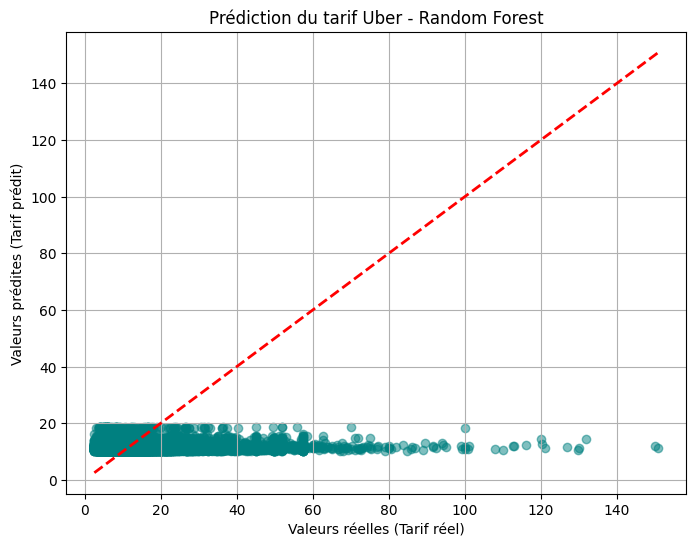

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.5, color='teal')
plt.xlabel('Valeurs réelles (Tarif réel)')
plt.ylabel('Valeurs prédites (Tarif prédit)')
plt.title('Prédiction du tarif Uber - Random Forest')

# Ligne diagonale de référence (prédiction parfaite y = x)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

plt.grid(True)
plt.show()


# EX2: Chargement et exploration
## Objectif
Prédire si un passager a survécu (1) ou non (0) au naufrage du Titanic à l'aide de modèles de classification en apprentissage supervisé (notamment la Régression Logistique et la Random Forest), en suivant un workflow complet : chargement des données, nettoyage, encodage, entraînement, évaluation et interprétation.

**Étape 1 : Chargement et exploration du jeu de données**

On charge le fichier de données Uber avec la bibliothèque `pandas`. Ensuite, on affiche les premières lignes pour observer la structure du tableau, on consulte les informations générales (types de variables, taille), et on identifie les éventuelles valeurs manquantes.


In [ ]:
import pandas as pd

# Chargement du fichier CSV du Titanic
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
data = pd.read_csv(url)

# 1. Afficher les premières lignes
print("--- 1. Aperçu des premières lignes ---")
display(data.head())

# 2. Afficher les informations sur les colonnes et les types de variables
print("\n--- 2. Informations générales ---")
print(data.info())

# 3. Identifier et compter les valeurs manquantes par colonne
print("\n--- 3. Valeurs manquantes ---")
print(data.isnull().sum())

--- 1. Aperçu des premières lignes ---


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



--- 2. Informations générales ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

--- 3. Valeurs manquantes ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fa

**Étape 2 : Nettoyage et traitement**

On sélectionne uniquement les colonnes utiles pour notre modèle (`Survived`, `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`). Ensuite, on remplace les valeurs manquantes de l'âge par la médiane et celles du port d'embarquement par la valeur la plus fréquente (le mode)



In [ ]:
# Sélection des colonnes utiles
data = data[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]

# Remplacement des valeurs manquantes de l'âge par la médiane
data['Age'] = data['Age'].fillna(data['Age'].median())

# Remplacement des valeurs manquantes d'embarquement par le mode (la valeur la plus fréquente)
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

# Vérification qu'il ne reste plus de valeurs manquantes
print("--- Valeurs manquantes après nettoyage ---")
print(data.isnull().sum())

--- Valeurs manquantes après nettoyage ---
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


 **Étape 3 : Encodage des variables catégorielles**

 Les algorithmes de Machine Learning ne peuvent manipuler que des nombres. Nous convertissons donc les colonnes textuelles (`Sex` et `Embarked`) en valeurs numériques à l'aide de l'outil `LabelEncoder`


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

# Transformation des colonnes texte en chiffres
data['Sex'] = le.fit_transform(data['Sex'])
data['Embarked'] = le.fit_transform(data['Embarked'])

# Affichage des premières lignes après encodage pour vérifier
print("--- Aperçu après encodage ---")
display(data.head())

--- Aperçu après encodage ---


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


**Étape 4 : Séparation des données**

On sépare notre tableau en deux : les variables explicatives (`X`, c'est-à-dire tout ce qui sert à deviner) et la variable cible (`y`, c'est-à-dire `Survived` qu'on veut prédire). Ensuite, on découpe ces données en un ensemble d'entraînement (80%) pour apprendre et un ensemble de test (20%) pour évaluer les performances.


In [ ]:
from sklearn.model_selection import train_test_split

# X = caractéristiques / y = cible à prédire
X = data.drop('Survived', axis=1)
y = data['Survived']

# Séparation des données (80% pour l'entraînement, 20% pour le test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Affichage des dimensions
print("Taille de l'ensemble d'entraînement (X_train) :", X_train.shape)
print("Taille de l'ensemble de test (X_test) :", X_test.shape)

Taille de l'ensemble d'entraînement (X_train) : (712, 7)
Taille de l'ensemble de test (X_test) : (179, 7)


 **Étape 5 : Entraînement des modèles**


Nous entraînons deux modèles de classification différents sur notre ensemble d'entraînement : un modèle linéaire (la **Régression Logistique**) et un modèle basé sur des arbres de décision multiples (la **Random Forest**).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Initialisation des deux modèles
log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Entraînement des modèles sur les données d'entraînement
log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("Modèles entraînés avec succès !")

Modèles entraînés avec succès !


**Étape 6 : Évaluation des modèles**


On évalue la précision (*Accuracy*) de nos deux modèles sur l'ensemble de test, puis on affiche un rapport de classification détaillé pour analyser plus finement les résultats de la Random Forest.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Prédictions sur le jeu de test
y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# Affichage des scores d'exactitude (Accuracy)
print('Accuracy (Logistic Regression) :', accuracy_score(y_test, y_pred_log))
print('Accuracy (Random Forest) :', accuracy_score(y_test, y_pred_rf))

# Rapport détaillé pour la Random Forest
print("\n--- Rapport de classification (Random Forest) ---")
print(classification_report(y_test, y_pred_rf))

Accuracy (Logistic Regression) : 0.8100558659217877
Accuracy (Random Forest) : 0.8212290502793296

--- Rapport de classification (Random Forest) ---
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179




  **Étape 7 : Matrice de confusion**


On trace une matrice de confusion sous forme de carte thermique (*heatmap*) pour visualiser graphiquement les bonnes et les mauvaises prédictions réalisées par notre modèle Random Forest.


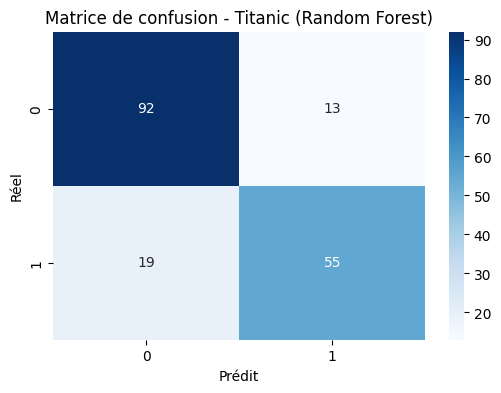

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calcul de la matrice de confusion
cm = confusion_matrix(y_test, y_pred_rf)

# Affichage sous forme de graphique
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion - Titanic (Random Forest)')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()

# Partie2: Mini-Projet : Prédiction des prix immobiliers (California Housing)
**Objectif :**

Appliquer un workflow d'apprentissage supervisé de bout en bout, comparer plusieurs modèles de régression, et justifier le choix du meilleur modèle de manière critique

In [12]:
# Importation des bibliothèques de base
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement alternatif et direct d'un dataset de régression propre (ex: California Housing via GitHub brut)
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
data = pd.read_csv(url)

print("--- Aperçu des données ---")
display(data.head())

print("\n--- Informations générales ---")
data.info()

--- Aperçu des données ---


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



--- Informations générales ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


**1. Prétraitement et Nettoyage des données**

- Suppression des valeurs manquantes.
- Encodage des variables catégorielles (ex: proximité de l'océan).
- Identification de la variable cible (`median_house_value`).

In [13]:
# Vérification des valeurs manquantes
print("Valeurs manquantes avant nettoyage :\n", data.isnull().sum())

# Suppression des lignes contenant des valeurs manquantes (ex: total_bedrooms)
data = data.dropna()

# Encodage de la variable catégorielle 'ocean_proximity' en variables indicatrices (One-Hot Encoding)
data = pd.get_dummies(data, columns=['ocean_proximity'], drop_first=True)

# Définition des features (X) et de la variable cible (y)
target_col = 'median_house_value'
X = data.drop(columns=[target_col])
y = data[target_col]

print("Prétraitement terminé. Forme finale de X :", X.shape)

Valeurs manquantes avant nettoyage :
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64
Prétraitement terminé. Forme finale de X : (20433, 12)


 **2. Séparation des données**

Division du jeu de données en un ensemble d'entraînement (80%) pour apprendre les modèles et un ensemble de test (20%) pour évaluer leurs performances.

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Taille de l'ensemble d'entraînement : {X_train.shape}")
print(f"Taille de l'ensemble de test : {X_test.shape}")

Taille de l'ensemble d'entraînement : (16346, 12)
Taille de l'ensemble de test : (4087, 12)


**3. Entraînement et Comparaison des Modèles**

Entraînement de trois modèles de régression aux comportements différents :
1. **Régression Linéaire** (Modèle linéaire de référence)
2. **Arbre de Décision** (Modèle non linéaire simple)
3. **Random Forest** (Modèle d'ensemble puissant)

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Dictionnaire des modèles
modeles = {
    "Régression Linéaire": LinearRegression(),
    "Arbre de Décision": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

resultats = []

# Entraînement et évaluation comparative
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    y_pred = modele.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    resultats.append({
        "Modèle": nom,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

# Affichage du tableau comparatif
df_resultats = pd.DataFrame(resultats)
print("--- TABLEAU COMPARATIF DES PERFORMANCES ---")
display(df_resultats)

--- TABLEAU COMPARATIF DES PERFORMANCES ---


,Modèle,MAE,RMSE,R²
0,Régression Linéaire,50413.433308,69297.716691,0.648840
1,Arbre de Décision,42798.084414,67296.330037,0.668831
2,Random Forest,31677.918808,48767.994521,0.826085


**4. Interprétation des Résultats**

- Visualisation graphique des performances du meilleur modèle (comparaison Réel vs Prédit).
- Analyse de l'importance des caractéristiques (Feature Importance).

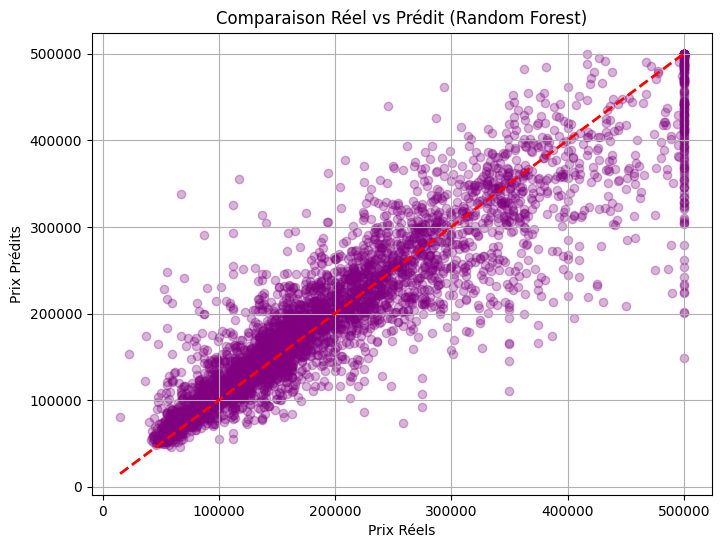

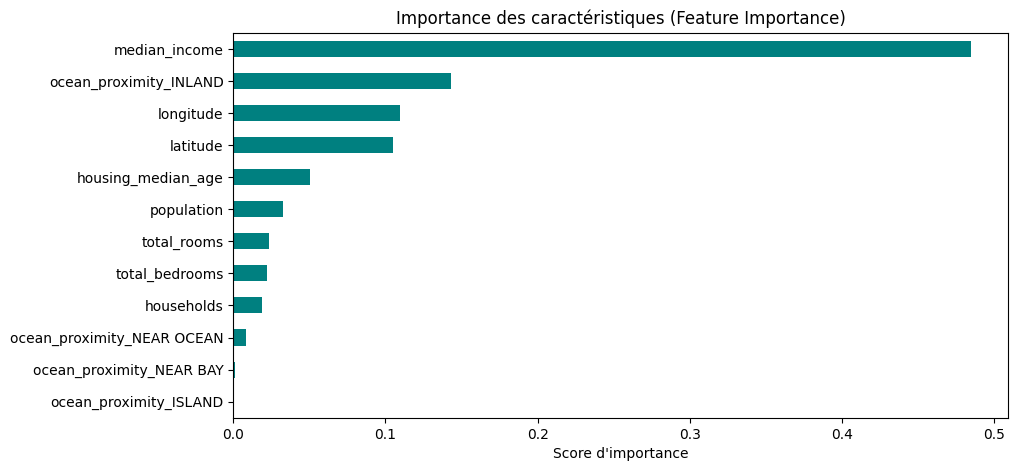

In [16]:
# Sélection du meilleur modèle (Random Forest)
meilleur_modele = modeles["Random Forest"]
y_pred_best = meilleur_modele.predict(X_test)

# Graphique : Valeurs réelles vs Valeurs prédites
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.3, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Prix Réels")
plt.ylabel("Prix Prédits")
plt.title("Comparaison Réel vs Prédit (Random Forest)")
plt.grid(True)
plt.show()

# Graphique : Importance des variables
importances = pd.Series(meilleur_modele.feature_importances_, index=X.columns)
plt.figure(figsize=(10, 5))
importances.sort_values().plot(kind='barh', color='teal')
plt.title("Importance des caractéristiques (Feature Importance)")
plt.xlabel("Score d'importance")
plt.show()